# 11B — Speed-state transfer and acceleration envelopes

**Primary hypothesis (declared, `m11.config.STUDIES` S11B).** Combine acceleration through a specific speed band (4 → 6, 6 → 8 yd/s) relates to NFL acceleration through the SAME band more strongly than to the broad season-average target (Milestone 05 primary `accel_sust05`). Test: within-position partial Spearman given the official forty and 10-yd split, matched minus broad, athlete bootstrap on the same athletes.

**Also:** observed NFL acceleration–speed envelopes `a(v) = A0 (1 − v/V0)` and three competing estimators (Huber, power family, nonparametric decreasing curve, plus frame-level quantile regression), Combine sprint physics `v(t) = Vmax (1 − e^(−(t − t0)/τ))` (offset fitted only when the onset is recorded) and its offset-free phase-plane form, direct transfer of these parameters, held-out ladder M1 → M1 + feature, negative controls, sensitivities.

**Not claimed.** An observed envelope is what an athlete did under game opportunity — not a physiological ceiling. No force is derived (no body-mass or drag model). Associations are descriptive; held-out gains are exploratory (one cohort).

**Prerequisites.** 11.0 (same `RUN_MODE`). **Run time.** One resumable pass over the tracking for the envelope histograms (checkpointed per season × game batch; an interrupted run resumes).

In [1]:
RUN_MODE = 'full'
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
SCAN_TRACKING = True          # False = reuse the saved envelope histograms of this run mode
RUN_PERMUTATION = True        # athlete-label permutation of the primary held-out pair (bounded: M11Config.n_perm)

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement.artifacts import DiscoveryStore
from nflbdb.research.advanced_movement.m11 import assemble as asm
from nflbdb.research.advanced_movement.m11 import combine_drills as cd
from nflbdb.research.advanced_movement.m11 import config as m11c
from nflbdb.research.advanced_movement.m11 import evaluation as ev
from nflbdb.research.advanced_movement.m11 import figures as fg
from nflbdb.research.advanced_movement.m11 import nfl_physics as nph
from nflbdb.research.advanced_movement.m11 import physics as ph
from nflbdb.research.advanced_movement.m11 import reporting as rp
from nflbdb.research.advanced_movement.m11 import sources as src
from nflbdb.research.advanced_movement.m11 import speed_state as ss
from nflbdb.research.advanced_movement.m11 import tournament as tn
from nflbdb.research.advanced_movement.m11 import validation as v11

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = DiscoveryStore(cfg, controls)
amc.seed_everything(controls.seed)
C = m11c.M11Config().for_mode(controls)
S = src.M11Sources(cfg, store, C)
PROV = m11c.provenance('11B', controls, C)
W = store.write_frame
officials = asm.foundation(store, 'm11_officials')
attempts = asm.foundation(store, 'm11_attempt_features')
athf = asm.foundation(store, 'm11_athlete_features')
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · config `{C.hash()}`'))

**Run mode: `full`** (FULL) · config `adfe53ee38110026`

In [3]:
checks = v11.run_all(v11.CHECKS_PHYSICS)
display(checks)
v11.assert_all_passed(checks)

check,status,detail
str,str,str
"""sprint_model_recovery""","""PASS""","""time-form and offset-free phas…"
"""envelope_recovery""","""PASS""","""upper-quantile envelope estima…"
"""outcome_construction""","""PASS""","""pairs and athlete-level target…"


## 1 · Combine sprint physics

Per forty attempt: time-form fit (offset only when the onset is recorded), offset-free phase-plane fit `a = A0 − (A0/V0) v`, band passages. Plausibility: agreement with the executed Phase 03 sprint profiles, model 40-yd time against the official forty (an offset is expected: reaction and timing conventions). Quality sensitivity: identifiable vs censored onsets.

check,n,spearman,median_difference
str,i64,f64,f64
"""forty.sprint_vmax vs Phase 03 …",758,0.9923,-0.003921
"""forty.sprint_tau vs Phase 03 m…",758,0.93014,-0.005
"""forty.phase_V0 vs Phase 03 mod…",758,0.967788,0.26574
"""model 40-yd time vs official f…",418,0.915503,0.272869
"""share of attempts with an iden…",793,NaN,0.918033


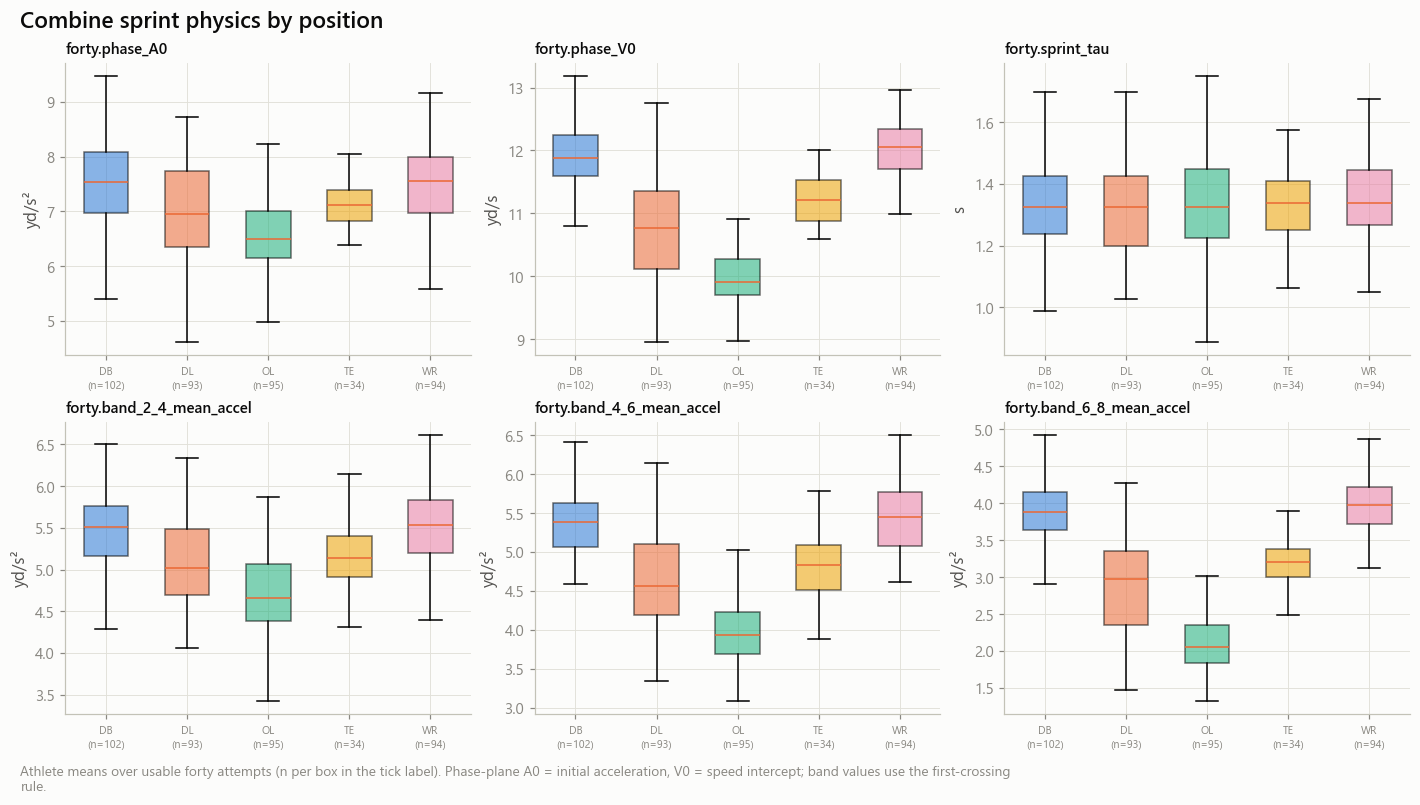

onset_identifiable,n_attempts,median_phase_A0,median_tau,median_r2
f64,u32,f64,f64,f64
0.0,65,5.87945,1.375,0.987442
1.0,728,7.228402,1.325,0.996546


In [4]:
sprint = ss.sprint_checks(attempts, S.phase03('combine_sprint_profiles'), officials)
W(sprint, 'm11_sprint_checks')
display(sprint)
FORTY = ['forty.phase_A0', 'forty.phase_V0', 'forty.sprint_tau', 'forty.band_2_4_mean_accel', 'forty.band_4_6_mean_accel', 'forty.band_6_8_mean_accel']
long = athf.filter(pl.col('feature').is_in(FORTY)).join(officials.select('nfl_id', 'position_group'), on='nfl_id', how='left')
units = {'forty.phase_A0': 'yd/s²', 'forty.phase_V0': 'yd/s', 'forty.sprint_tau': 's', 'forty.band_2_4_mean_accel': 'yd/s²', 'forty.band_4_6_mean_accel': 'yd/s²', 'forty.band_6_8_mean_accel': 'yd/s²'}
store.show(fg.fig_distributions(long, 'feature', 'value', 'position_group', FORTY, 'Combine sprint physics by position',
                                'Athlete means over usable forty attempts (n per box in the tick label). Phase-plane A0 = initial acceleration, V0 = speed intercept; band values use the first-crossing rule.', units),
           'AM11_B_01_sprint_physics_distributions', {'sprint_long': long}, publication=True, source='m11_athlete_features', n=f"{long['nfl_id'].n_unique()} athletes")
w = attempts.filter(pl.col('family') == 'forty').pivot(on='feature', index=['seq_id', 'nfl_id'], values='value')
sens = (w.group_by(pl.col('forty.sprint_offset_identifiable').alias('onset_identifiable')).agg(pl.len().alias('n_attempts'), pl.col('forty.phase_A0').median().alias('median_phase_A0'),
        pl.col('forty.sprint_tau').median().alias('median_tau'), pl.col('forty.sprint_r2').median().alias('median_r2')) if 'forty.sprint_offset_identifiable' in w.columns else pl.DataFrame())
W(sens, 'm11_sprint_censoring_sensitivity')
display(sens)

## 2 · NFL acceleration–speed envelopes (one resumable tracking scan)

Athlete × game × speed bin (0.5 yd/s) × acceleration bin (0.25 yd/s²) frame counts of eligible post-snap, non-boundary frames. Per athlete: the 95th percentile of a_tan per speed bin (≥ `env_min_frames_bin` frames), then the linear, Huber, power-family and nonparametric envelopes and a frame-level quantile regression. Game bootstrap (`env_boot` replicates) gives intervals for the linear A0 / V0 and the envelope at band mid-speeds. Frames are dependent: quantiles are descriptive and only athletes are counted as a sample.

22:41:51 | INFO    | nflbdb.research.advanced_movement.m11.nfl_physics | [m11.envelope] season 2023 batch 2: 1,574 cells (0s)
22:41:52 | INFO    | nflbdb.research.advanced_movement.m11.nfl_physics | [m11.envelope] season 2023 batch 3: 39,727 cells (1s)
22:41:53 | INFO    | nflbdb.research.advanced_movement.m11.nfl_physics | [m11.envelope] season 2023 batch 4: 34,185 cells (2s)
22:41:53 | INFO    | nflbdb.research.advanced_movement.m11.nfl_physics | [m11.envelope] season 2023 batch 5: 41,264 cells (3s)
22:41:54 | INFO    | nflbdb.research.advanced_movement.m11.nfl_physics | [m11.envelope] season 2023 batch 6: 43,768 cells (3s)
22:41:55 | INFO    | nflbdb.research.advanced_movement.m11.nfl_physics | [m11.envelope] season 2023 batch 7: 41,622 cells (4s)
22:41:55 | INFO    | nflbdb.research.advanced_movement.m11.nfl_physics | [m11.envelope] season 2023 batch 8: 48,665 cells (5s)
22:41:56 | INFO    | nflbdb.research.advanced_movement.m11.nfl_physics | [m11.envelope] season 2023 batch 9: 51,

[envelopes] 1/401 · elapsed 0s · ETA 45s 
[envelopes] 331/401 · elapsed 30s · ETA 6s 
[envelopes] 401/401 · elapsed 35s · ETA 0s 
[envelopes] 1/722 · elapsed 0s · ETA 27s 
[envelopes] 722/722 · elapsed 19s · ETA 0s 
401 athletes in the histograms · 388 with a supported envelope


statistic,lin_A0,lin_V0,hub_A0,hub_V0,pow_A0,pow_V0,pow_k,qr_A0,qr_V0
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",401.0,401.0,401.0,401.0,401.0,401.0,401.0,401.0,401.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"""std""",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"""min""",2.456901,6.658515,2.400293,6.405023,2.390671,5.318644,0.5,2.375,6.849999
"""25%""",3.998301,10.872568,4.017714,10.659865,4.201708,8.903983,1.5,4.031249,10.636363
"""50%""",5.35572,12.067603,5.447508,11.646522,4.740328,9.8475,2.1,5.5,11.449996
"""75%""",6.410221,13.863571,6.54306,13.713368,5.330953,10.501907,2.5,6.791665,13.250019
"""max""",10.239275,61.386207,10.16627,212.036285,8.198414,15.530975,3.0,10.0625,4.0375e7


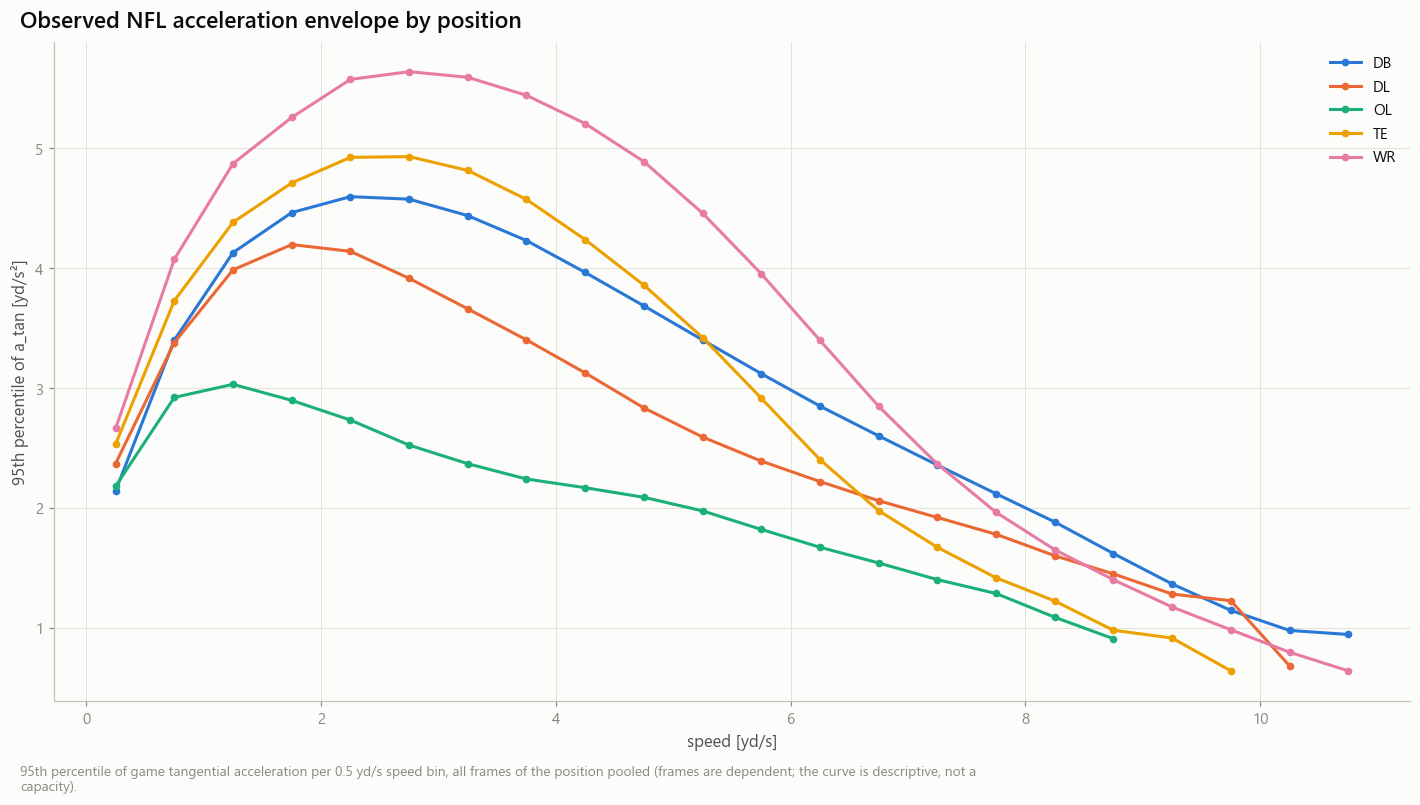

In [5]:
plays = S.plays()
if SCAN_TRACKING or not store.has('m11_envelope_hist'):
    builder = nph.EnvelopeBuilder(cfg, C, S.oc, store.shards_dir, controls.run_mode, limit_games=C.smoke_games if controls.smoke else None)
    hist = builder.compute(plays)
    W(hist, 'm11_envelope_hist', csv=False)
else:
    hist = store.read_frame('m11_envelope_hist', '11B')
env = nph.envelope_table(hist, C, seed=C.seed)
env_season = nph.envelope_table(hist, C, by=('nfl_id', 'season'), n_boot=0, seed=C.seed)
pos_env = nph.position_envelopes(hist, officials, C)
W(env, 'm11_envelopes')
W(env_season, 'm11_envelopes_season')
W(pos_env, 'm11_position_envelopes')
n_sup = int(env['supported'].sum()) if env.height else 0
print(f"{hist['nfl_id'].n_unique()} athletes in the histograms · {n_sup} with a supported envelope")
display(env.select('lin_A0', 'lin_V0', 'hub_A0', 'hub_V0', 'pow_A0', 'pow_V0', 'pow_k', 'qr_A0', 'qr_V0').describe())
store.show(fg.fig_envelopes(pos_env, 'Observed NFL acceleration envelope by position',
                            '95th percentile of game tangential acceleration per 0.5 yd/s speed bin, all frames of the position pooled (frames are dependent; the curve is descriptive, not a capacity).'),
           'AM11_B_02_nfl_envelopes_by_position', {'position_envelopes': pos_env}, publication=True, source='m11_envelope_hist', n=f'{n_sup} athletes with a supported envelope')

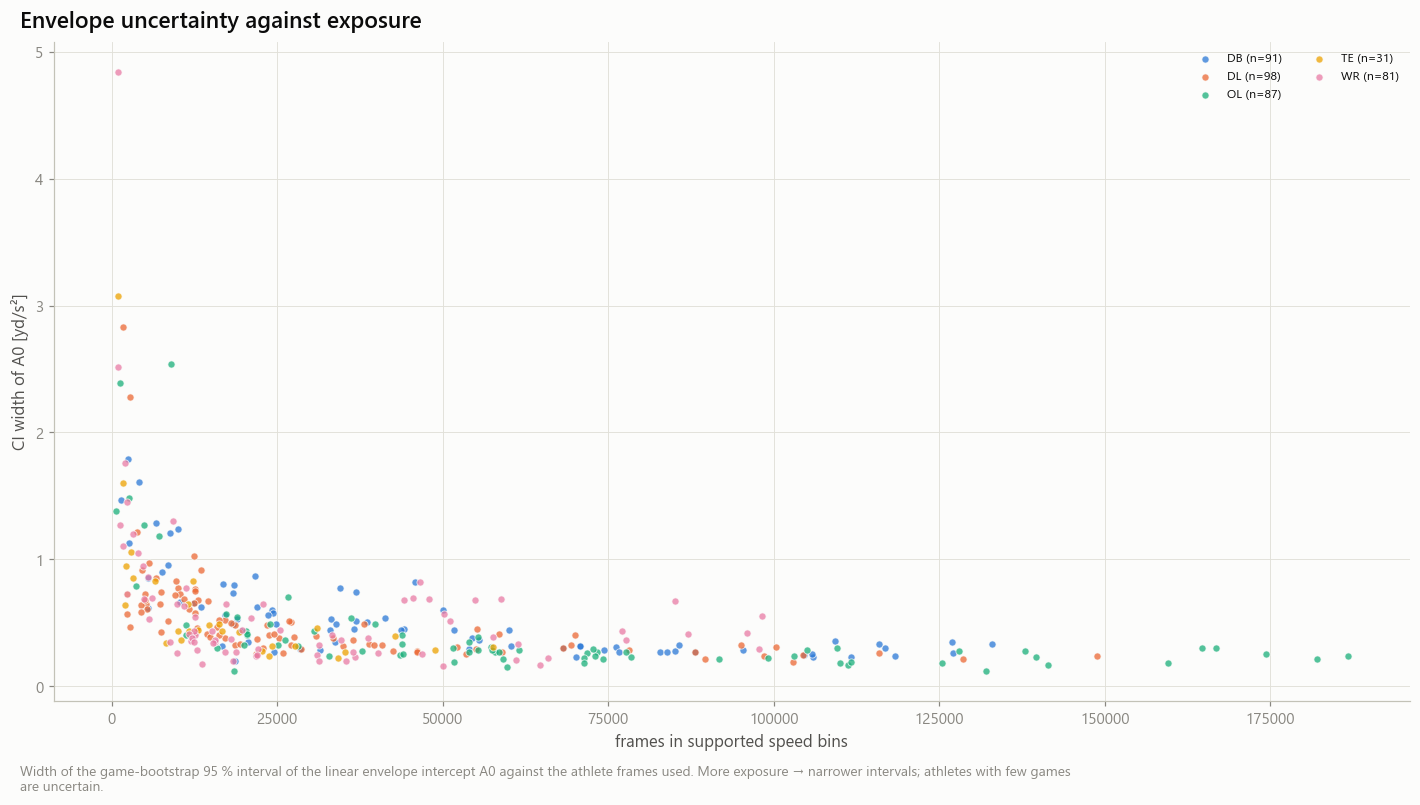

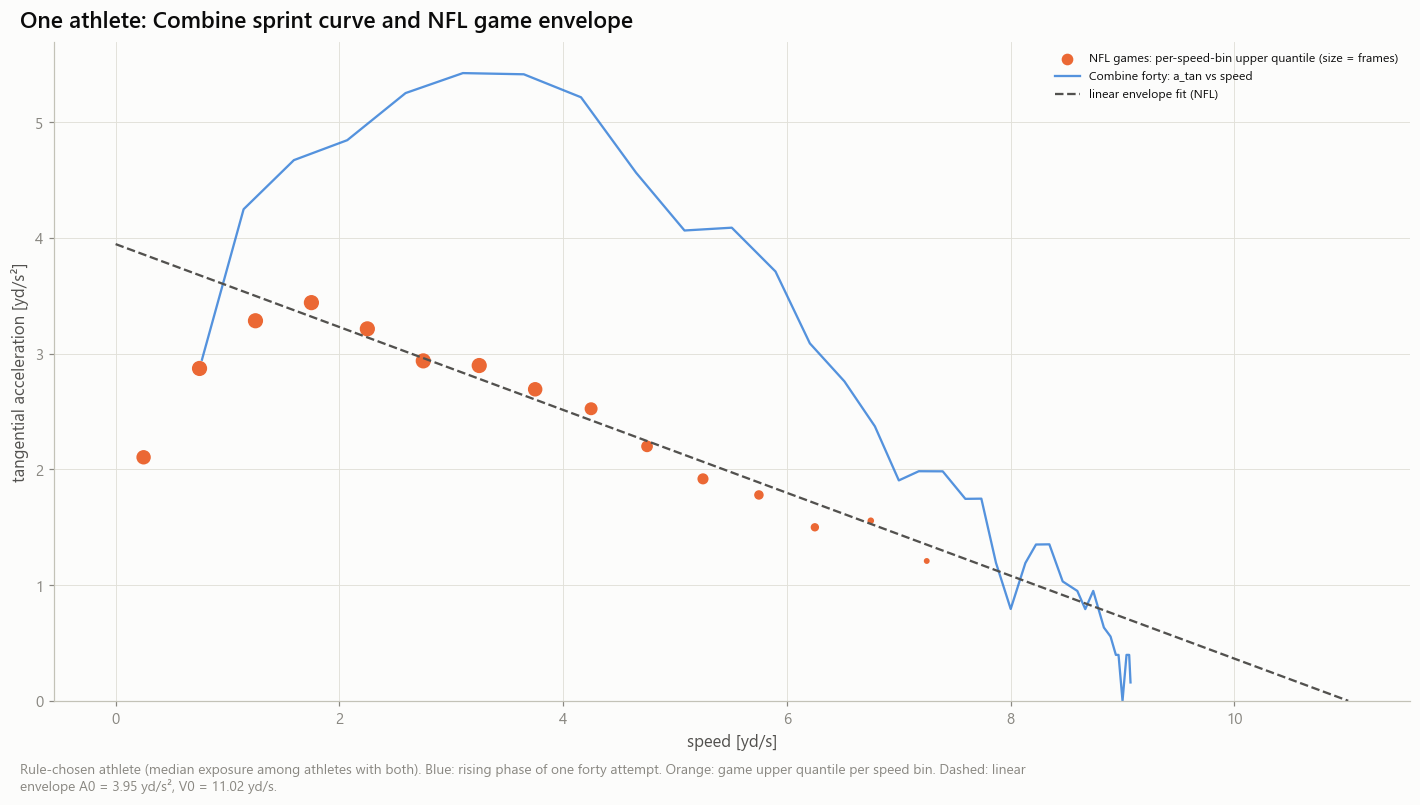

In [6]:
# envelope uncertainty and a rule-chosen individual overlay (the supported athlete with the median frame count who also has a usable forty)
supp = env.filter(pl.col('supported') & pl.col('lin_A0_se').is_not_null())
unc = supp.select('nfl_id', 'lin_A0', 'lin_A0_lo', 'lin_A0_hi', 'n_frames').join(officials.select('nfl_id', 'position_group'), on='nfl_id', how='left')
store.show(fg.fig_scatter(unc.with_columns((pl.col('lin_A0_hi') - pl.col('lin_A0_lo')).alias('ci_width')), 'n_frames', 'ci_width', 'Envelope uncertainty against exposure',
                          'Width of the game-bootstrap 95 % interval of the linear envelope intercept A0 against the athlete frames used. More exposure → narrower intervals; athletes with few games are uncertain.',
                          'frames in supported speed bins', 'CI width of A0 [yd/s²]'), 'AM11_B_03_envelope_uncertainty', {'uncertainty': unc}, publication=False, source='m11_envelopes')
both = supp.join(athf.filter(pl.col('feature') == 'forty.phase_A0').select('nfl_id'), on='nfl_id', how='inner').sort('n_frames', 'nfl_id')
if both.height:
    pick = int(both['nfl_id'][both.height // 2])
    pts = nph.athlete_points(hist, pick, C)
    fr = S.combine_frames(['forty'])
    sid = fr.filter(pl.col('nfl_id') == pick)['seq_id'].unique().sort()[0]
    f = cd.longest_segment(fr.filter(pl.col('seq_id') == sid))
    vv, aa = f['speed'].to_numpy(), f['a_tan'].to_numpy()
    k = int(np.nanargmax(vv)) + 1
    r = env.filter(pl.col('nfl_id') == pick).row(0, named=True)
    store.show(fg.fig_athlete_overlay(pts, vv[:k], aa[:k], {'A0': r['lin_A0'], 'V0': r['lin_V0']}, 'One athlete: Combine sprint curve and NFL game envelope',
                                      f'Rule-chosen athlete (median exposure among athletes with both). Blue: rising phase of one forty attempt. Orange: game upper quantile per speed bin. Dashed: linear envelope A0 = {r["lin_A0"]:.2f} yd/s², V0 = {r["lin_V0"]:.2f} yd/s.'),
               'AM11_B_04_individual_overlay', {'nfl_points': pts}, publication=True, source='m11_envelope_hist + combine frames')

## 3 · Direct transfer (association and held-out ladder)

For every declared pair (`speed_state.PAIRS`): Pearson, Spearman with athlete-bootstrap CI, partial Spearman given official forty and 10-yd split, attenuation-corrected Pearson (Combine ICC × NFL split-half / envelope bootstrap reliability; not reported below 0.3), median within-position Spearman, minimum detectable correlation at this n. Held-out: M1 (context + official) vs M1 + the Combine feature, athlete folds of 11.0.

combine,nfl,kind,n_athletes,spearman,spearman_lo,spearman_hi,partial_spearman,pearson_disattenuated,within_position_spearman,mde_r,reading
str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,str
"""forty.band_2_4_mean_accel""","""nfl.band_2_4""","""matched""",309,0.444236,0.348106,0.533571,0.109024,0.543183,0.234188,0.159313,"""association (interval excludes 0) — descriptive"""
"""forty.band_4_6_mean_accel""","""nfl.band_4_6""","""matched""",237,0.548499,0.437879,0.643148,0.098261,0.685463,0.143734,0.181887,"""association (interval excludes 0) — descriptive"""
"""forty.band_6_8_mean_accel""","""nfl.band_6_8""","""matched""",120,0.392451,0.219886,0.55178,0.072713,0.349716,0.310054,0.255464,"""association (interval excludes 0) — descriptive"""
"""forty.band_8_10_mean_accel""","""env.env_8_10""","""matched""",116,0.209203,0.020918,0.368853,0.012348,NaN,0.334819,0.259819,"""association (interval excludes 0) — descriptive"""
"""forty.band_2_4_mean_accel""","""nfl.band_6_8""","""noncomparable""",120,0.068178,-0.095566,0.247914,0.008887,0.076901,0.058865,0.255464,"""inconclusive (|r| below ≈ 0.26 is not detectable at this n)"""
"""forty.band_6_8_mean_accel""","""nfl.band_2_4""","""noncomparable""",309,0.700188,0.618049,0.765105,0.088412,0.762858,0.229402,0.159313,"""association (interval excludes 0) — descriptive"""
"""forty.band_4_6_mean_accel""","""nfl.broad_accel_sust05""","""broad""",323,0.656303,0.578277,0.725029,0.149962,0.771452,0.134574,0.155825,"""association (interval excludes 0) — descriptive"""
"""forty.band_6_8_mean_accel""","""nfl.broad_accel_sust05""","""broad""",323,0.722559,0.654236,0.779055,0.120738,0.780538,0.08605,0.155825,"""association (interval excludes 0) — descriptive"""
"""forty.band_2_4_mean_accel""","""nfl.broad_accel_sust05""","""broad""",323,0.461643,0.369801,0.551391,0.111324,0.573959,0.138598,0.155825,"""association (interval excludes 0) — descriptive"""


combine,target,kind,n_athletes,delta_rmse,delta_lo,delta_hi,delta_pct,verdict
str,str,str,i64,f64,f64,f64,f64,str
"""forty.band_2_4_mean_accel""","""nfl.band_2_4""","""matched""",309,-0.000068,-0.000621,0.000592,-0.026037,"""inconclusive"""
"""forty.band_4_6_mean_accel""","""nfl.band_4_6""","""matched""",237,0.000335,-0.000656,0.001429,0.182035,"""inconclusive"""
"""forty.band_6_8_mean_accel""","""nfl.band_6_8""","""matched""",120,-0.001371,-0.00328,0.00036,-0.871826,"""inconclusive"""
"""forty.band_8_10_mean_accel""","""env.env_8_10""","""matched""",116,-0.003286,-0.0085,0.001881,-1.893045,"""inconclusive"""
"""forty.band_4_6_mean_accel""","""nfl.broad_accel_sust05""","""broad""",323,-0.000559,-0.00134,0.000163,-0.222597,"""inconclusive"""
"""forty.band_6_8_mean_accel""","""nfl.broad_accel_sust05""","""broad""",323,0.000346,-0.000786,0.001594,0.137782,"""inconclusive"""
"""forty.band_2_4_mean_accel""","""nfl.broad_accel_sust05""","""broad""",323,-0.000313,-0.000879,0.000294,-0.124474,"""inconclusive"""
"""forty.phase_A0""","""env.lin_A0""","""physics""",323,-0.000154,-0.003068,0.002729,-0.029169,"""inconclusive"""
"""forty.phase_V0""","""env.lin_V0""","""physics""",321,-0.001268,-0.002835,-0.000157,-0.03271,"""model_worse"""


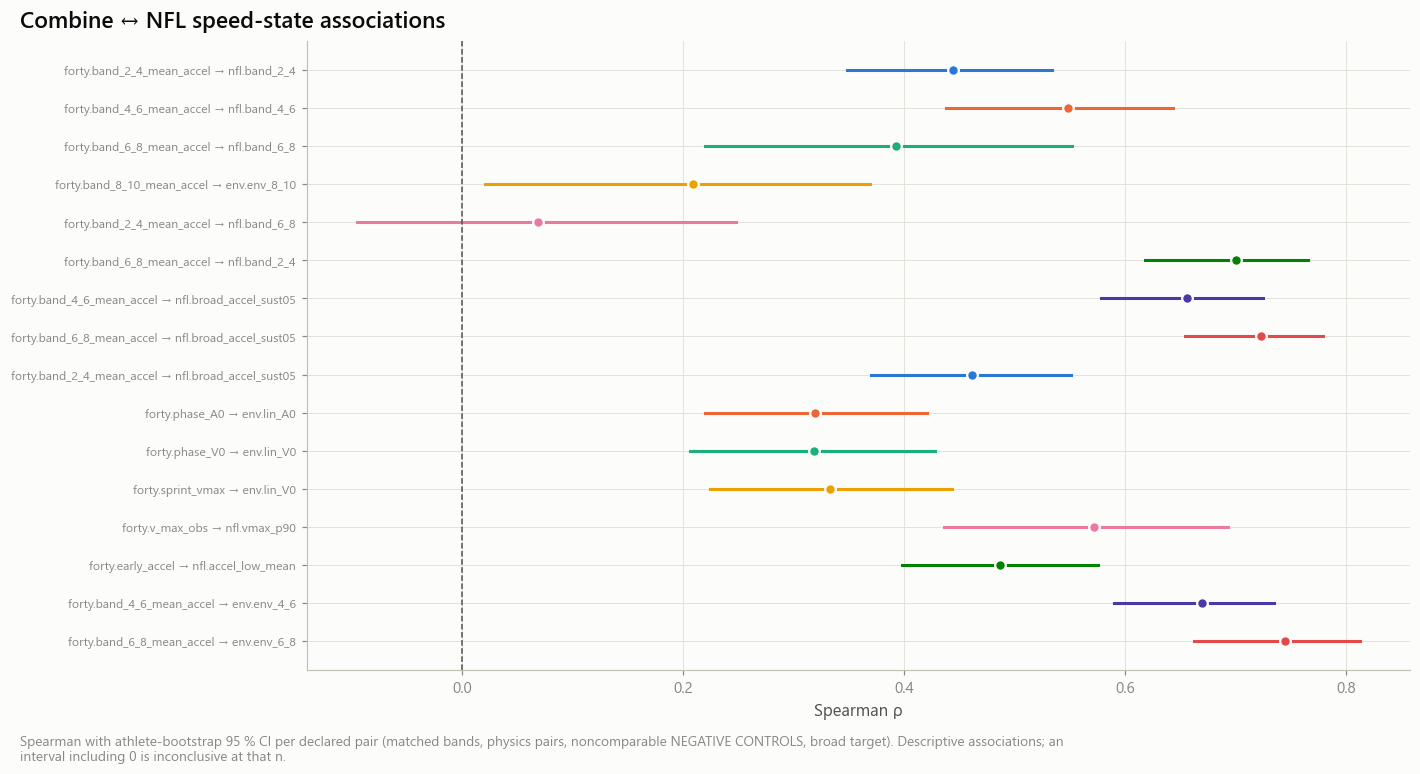

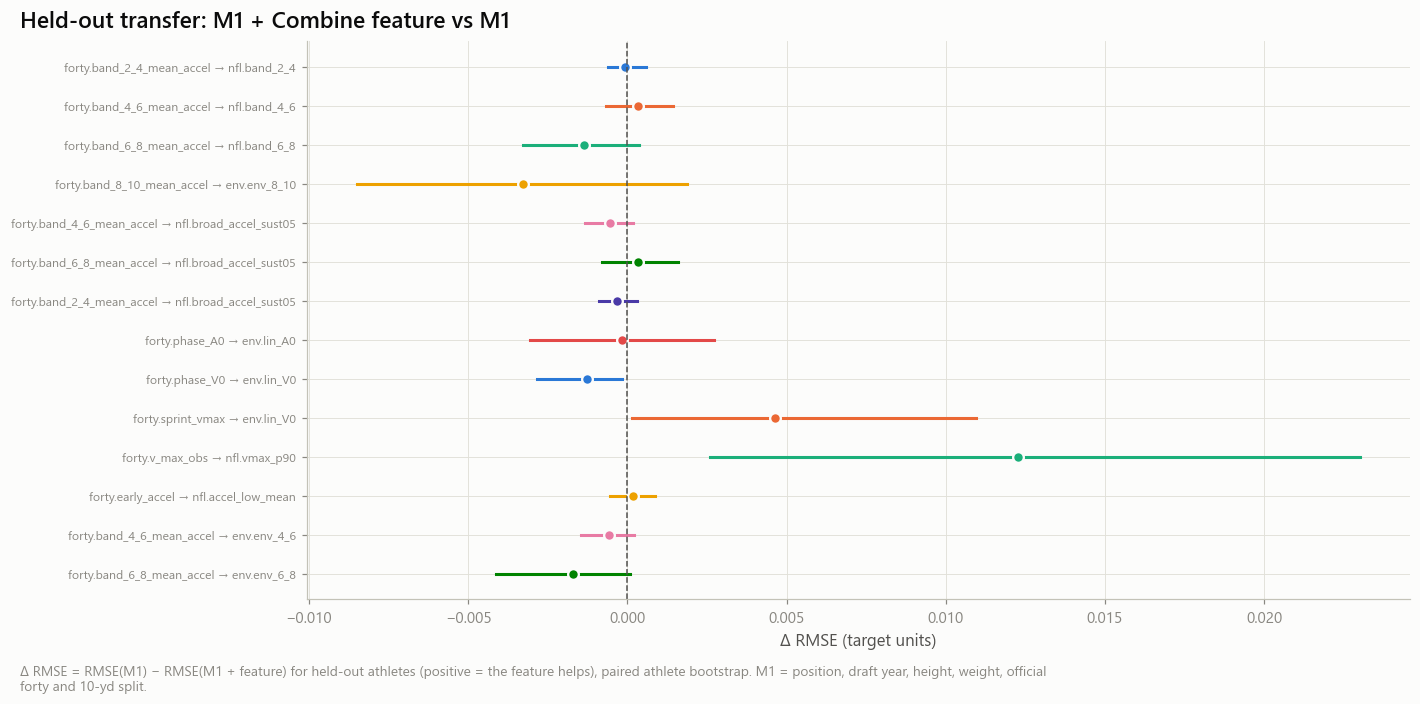

In [7]:
envw = ss.envelope_wide(env, 'lin')
data = asm.linked_table(store, extra=[envw], nfl_required=False)
data = data.filter(pl.any_horizontal([pl.col(c).is_not_null() for c in data.columns if c.startswith(('nfl.', 'env.'))]))
RELMAP = asm.reliability_map(store)
for k in ('lin_A0', 'lin_V0'):
    s_ = supp.select(pl.col(k).var().alias('v'), (pl.col(f'{k}_se') ** 2).mean().alias('e')).row(0, named=True) if supp.height > 5 else None
    if s_ and s_['v'] and s_['v'] > 0:
        RELMAP[f'env.{k}'] = float(max(0.0, 1 - s_['e'] / s_['v']))
assoc, held = ss.direct_transfer(data.drop('fold', 'fold_source'), ss.PAIRS, RELMAP, data.select('nfl_id', 'fold'), C, C.seed)
W(assoc, 'm11_speed_state_assoc')
W(held, 'm11_speed_state_heldout')
with pl.Config(tbl_rows=-1, tbl_width_chars=260, fmt_str_lengths=60):
    display(assoc.select('combine', 'nfl', 'kind', 'n_athletes', 'spearman', 'spearman_lo', 'spearman_hi', 'partial_spearman', 'pearson_disattenuated', 'within_position_spearman', 'mde_r', 'reading'))
    display(held.select('combine', 'target', 'kind', 'n_athletes', 'delta_rmse', 'delta_lo', 'delta_hi', 'delta_pct', 'verdict') if held.height else held)
fa = assoc.filter(pl.col('status') == 'computed').with_columns((pl.col('combine') + ' → ' + pl.col('nfl')).alias('pair'))
store.show(fg.fig_forest(fa, 'pair', 'spearman', 'spearman_lo', 'spearman_hi', 'Combine ↔ NFL speed-state associations',
                         'Spearman with athlete-bootstrap 95 % CI per declared pair (matched bands, physics pairs, noncomparable NEGATIVE CONTROLS, broad target). Descriptive associations; an interval including 0 is inconclusive at that n.',
                         'Spearman ρ', color_by='kind'), 'AM11_B_05_transfer_forest', {'assoc': fa}, publication=True, source='m11_speed_state_assoc')
if held.height:
    hf = held.with_columns((pl.col('combine') + ' → ' + pl.col('target')).alias('pair'))
    store.show(fg.fig_forest(hf, 'pair', 'delta_rmse', 'delta_lo', 'delta_hi', 'Held-out transfer: M1 + Combine feature vs M1',
                             'Δ RMSE = RMSE(M1) − RMSE(M1 + feature) for held-out athletes (positive = the feature helps), paired athlete bootstrap. M1 = position, draft year, height, weight, official forty and 10-yd split.',
                             'Δ RMSE (target units)', color_by='kind'), 'AM11_B_06_heldout_forest', {'heldout': hf}, publication=True, source='m11_speed_state_heldout')

## 4 · PRIMARY — matched speed band vs broad target

Same athletes, same Combine feature, two NFL targets. Positive difference with an interval above 0 = the matched band carries more of the Combine relation than the season-average target.

combine,matched,n_athletes,partial_matched,partial_broad,difference,diff_lo,diff_hi,verdict,status
str,str,i64,f64,f64,f64,f64,f64,str,str
"""forty.band_4_6_mean_accel""","""nfl.band_4_6""",237,0.098261,0.129462,-0.031201,-0.104246,0.042673,"""inconclusive""","""computed"""
"""forty.band_6_8_mean_accel""","""nfl.band_6_8""",120,0.072713,0.057475,0.015237,-0.219931,0.249201,"""inconclusive""","""computed"""


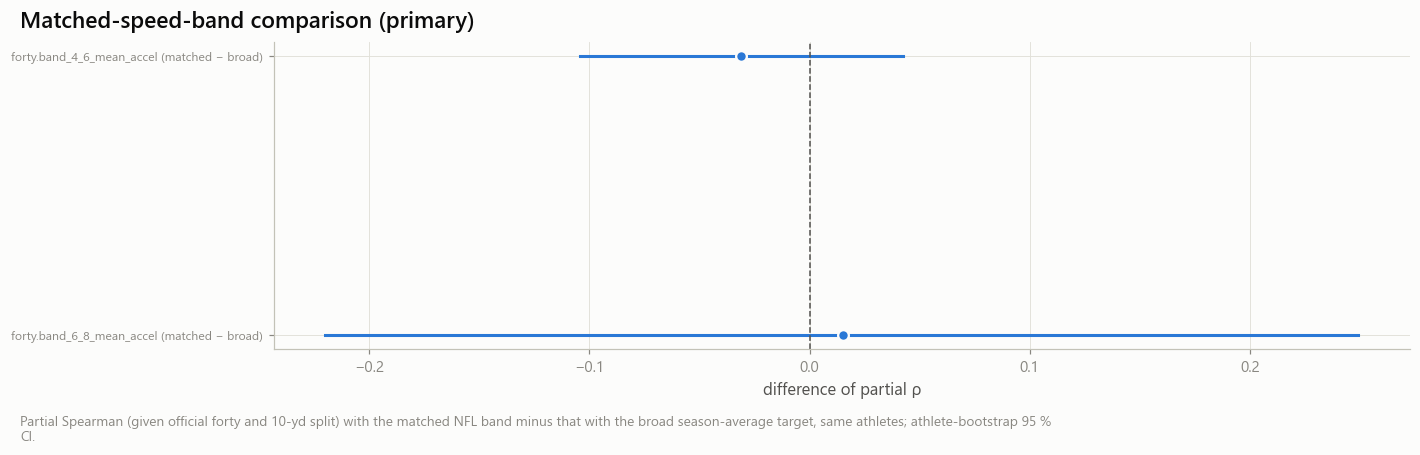

In [8]:
prim = ss.matched_vs_broad(data, C, C.seed)
W(prim, 'm11_speed_state_primary')
display(prim)
pf = prim.filter(pl.col('status') == 'computed').with_columns((pl.col('combine') + ' (matched − broad)').alias('label'))
store.show(fg.fig_forest(pf, 'label', 'difference', 'diff_lo', 'diff_hi', 'Matched-speed-band comparison (primary)',
                         'Partial Spearman (given official forty and 10-yd split) with the matched NFL band minus that with the broad season-average target, same athletes; athlete-bootstrap 95 % CI.',
                         'difference of partial ρ'), 'AM11_B_07_matched_vs_broad', {'primary': pf}, publication=True, source='m11_speed_state_primary')

## 5 · Negative controls and position subgroups

Controls: noncomparable band pairs (already in section 3) and an athlete-label permutation of the primary held-out pair (tracking block permuted within position, both models refitted). Subgroups: the matched pairs by position, with their own athlete counts.

observed,null_mean,null_q95,p_value,n_perm,random_projection_q95
f64,f64,f64,f64,i64,f64
0.000335,-0.000363,0.001202,0.139303,200,0.000655


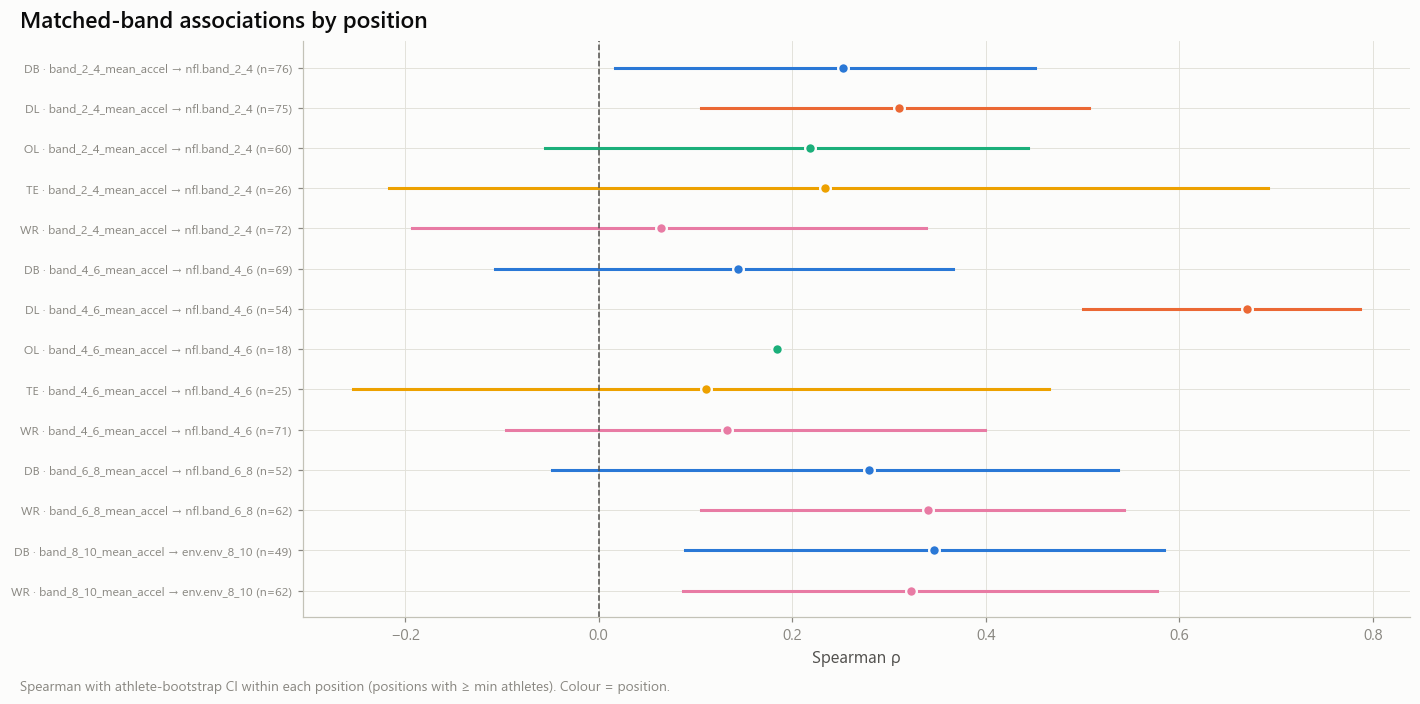

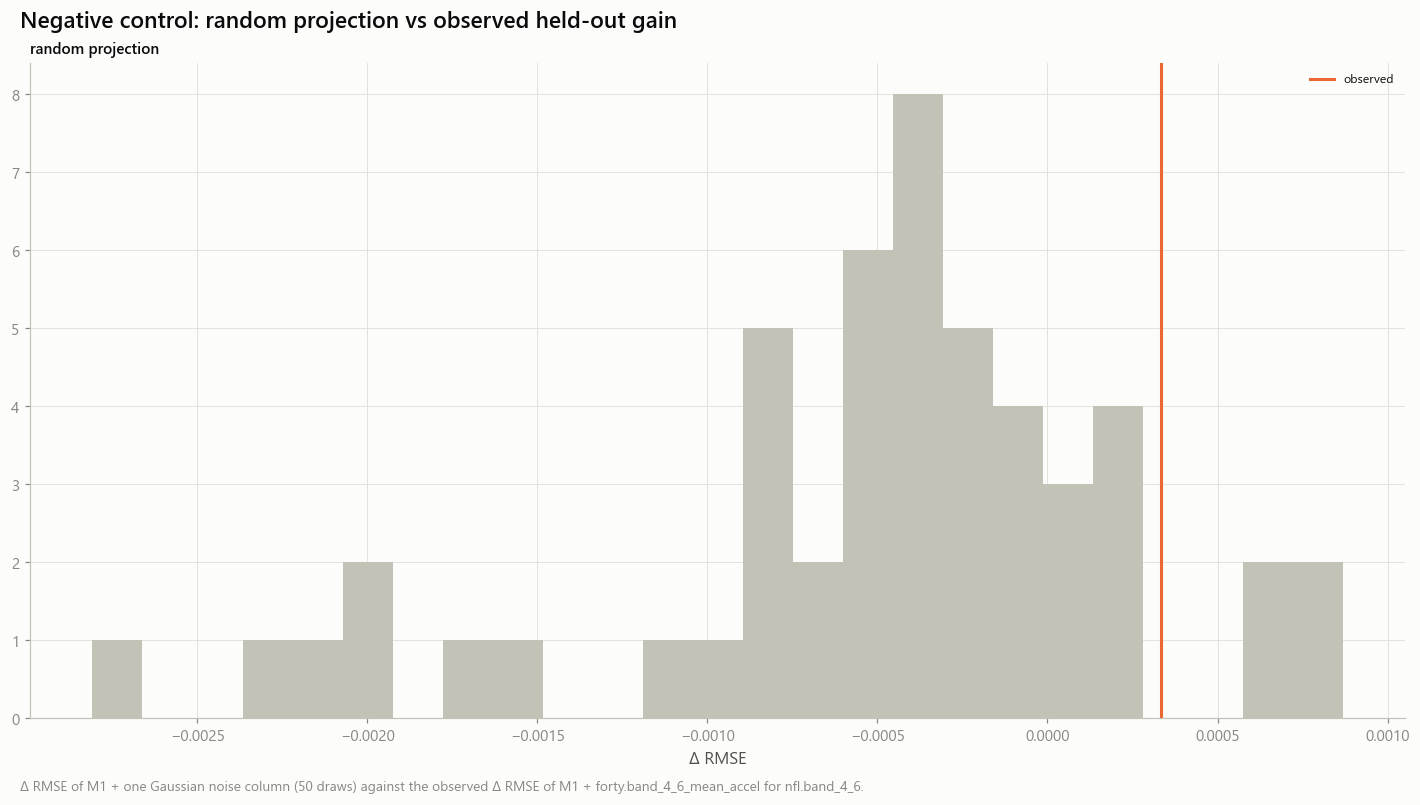

In [9]:
nulls, obs = {}, {}
feat, tgt = 'forty.band_4_6_mean_accel', 'nfl.band_4_6'
if RUN_PERMUTATION and feat in data.columns and tgt in data.columns:
    sub = data.filter(pl.col(feat).is_not_null() & pl.col(tgt).is_not_null())
    base = [*ev.CONTEXT, *ev.OFFICIAL_CORE]
    pn = ev.permutation_null(sub, tgt, base, [*base, feat], sub['fold'].to_numpy(), C, C.seed)
    rp_ = ev.random_projection_control(sub, tgt, base, 1, sub['fold'].to_numpy(), C, C.seed)
    obs['athlete-label permutation'] = obs['random projection'] = pn['observed']
    nulls['athlete-label permutation'] = np.array([pn['null_mean']]) if pn['n_perm'] == 0 else None
    W(pl.DataFrame([{**pn, 'feature': feat, 'target': tgt, 'random_q95': float(np.quantile(rp_, 0.95)) if rp_.size else None}]), 'm11_speed_state_controls')
    display(pl.DataFrame([{**pn, 'random_projection_q95': float(np.quantile(rp_, 0.95)) if rp_.size else None}]))
    nulls = {'random projection': rp_}
rows = []
for p in [p for p in ss.PAIRS if p.kind == 'matched']:
    if p.combine not in data.columns or p.nfl not in data.columns:
        continue
    for (pos,), g in sorted(data.partition_by(['position_group'], as_dict=True).items()):
        r = ev.association(g[p.combine].cast(pl.Float64).to_numpy(), g[p.nfl].cast(pl.Float64).to_numpy(), None, max(200, C.n_boot // 5), C.seed)
        if r['n_athletes'] >= C.min_athletes_limited:
            rows.append({'pair': p.combine.split('.')[-1] + ' → ' + p.nfl, 'position_group': pos, **{k: r[k] for k in ('n_athletes', 'spearman', 'spearman_lo', 'spearman_hi')}})
subg = pl.DataFrame(rows) if rows else pl.DataFrame()
W(subg, 'm11_speed_state_by_position')
if subg.height:
    sg_ = subg.with_columns((pl.col('position_group') + ' · ' + pl.col('pair') + ' (n=' + pl.col('n_athletes').cast(pl.String) + ')').alias('label'))
    store.show(fg.fig_forest(sg_, 'label', 'spearman', 'spearman_lo', 'spearman_hi', 'Matched-band associations by position',
                             'Spearman with athlete-bootstrap CI within each position (positions with ≥ min athletes). Colour = position.', 'Spearman ρ', color_by='position_group'),
               'AM11_B_08_by_position', {'by_position': sg_}, publication=False, source='m11_speed_state_by_position')
if nulls:
    store.show(fg.fig_null_vs_observed(nulls, obs, 'Negative control: random projection vs observed held-out gain',
                                       f'Δ RMSE of M1 + one Gaussian noise column ({C.n_random_projections} draws) against the observed Δ RMSE of M1 + {feat} for {tgt}.', 'Δ RMSE'),
               'AM11_B_09_negative_control', {}, publication=False, source='m11_speed_state_controls')

## 6 · Sensitivities

Exposure thresholds (athlete targets need ≥ k episodes), first NFL season only vs later seasons, envelope estimator (linear · Huber · power · quantile regression), excluding athletes whose forty onsets are all censored. Each variant recomputes the matched / physics associations; none replaces the primary.

In [10]:
variants = {}
for k in C.exposure_grid:
    variants[f'min_episodes_{k}'] = asm.linked_table(store, extra=[envw], nfl_required=False, min_episodes=k)
episodes = S.episodes()
pairs = asm.foundation(store, 'm11_brake_reaccel_pairs')
first = episodes.group_by('nfl_id').agg(pl.col('season').min().alias('_f'))
for name, cond in (('first_season_only', pl.col('season') == pl.col('_f')), ('later_seasons_only', pl.col('season') > pl.col('_f'))):
    e2 = episodes.join(first, on='nfl_id').filter(cond).drop('_f')
    t2 = nph.athlete_targets(e2, pairs.join(first, on='nfl_id').filter(cond).drop('_f'), None, C)
    variants[name] = officials.join(cd.wide(athf), on='nfl_id', how='left').join(ss.nfl_wide(t2), on='nfl_id', how='inner').join(envw, on='nfl_id', how='left')
for est in ('hub', 'pow', 'qr'):
    variants[f'envelope_{est}'] = officials.join(cd.wide(athf), on='nfl_id', how='left').join(ss.envelope_wide(env, est), on='nfl_id', how='inner')
if 'forty.onset_censored' in w.columns:
    cens = w.group_by('nfl_id').agg(pl.col('forty.onset_censored').min().alias('_c')).filter(pl.col('_c') < 1)['nfl_id']
    variants['onset_recorded_only'] = data.filter(pl.col('nfl_id').is_in(cens.to_list()))
sens = ss.sensitivity_rows(data, variants, ss.PAIRS, C, C.seed)
W(sens, 'm11_speed_state_sensitivity')
with pl.Config(tbl_rows=-1, tbl_width_chars=220):
    display(sens.pivot(on='variant', index=['combine', 'nfl'], values='spearman'))

combine,nfl,primary,min_episodes_10,min_episodes_25,min_episodes_50,first_season_only,later_seasons_only,envelope_hub,envelope_pow,envelope_qr,onset_recorded_only
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""forty.band_2_4_mean_accel""","""nfl.band_2_4""",0.444236,0.444236,0.437573,0.415954,0.444185,0.404881,null,null,null,0.470255
"""forty.band_4_6_mean_accel""","""nfl.band_4_6""",0.548499,0.548499,0.367064,0.278516,0.452502,0.581175,null,null,null,0.553189
"""forty.band_6_8_mean_accel""","""nfl.band_6_8""",0.392451,0.392451,0.350372,0.259684,0.267693,0.383695,null,null,null,0.367055
"""forty.band_8_10_mean_accel""","""env.env_8_10""",0.209203,0.209203,0.209203,0.209203,0.186424,0.228704,0.209203,0.209203,0.209203,0.206077
"""forty.phase_A0""","""env.lin_A0""",0.319295,0.319295,0.319295,0.319295,0.311397,0.281246,0.321776,0.272865,0.318457,0.352614
"""forty.phase_V0""","""env.lin_V0""",0.318666,0.318666,0.318666,0.318666,0.307833,0.263974,0.254199,-0.021002,0.196902,0.332346
"""forty.sprint_vmax""","""env.lin_V0""",0.332671,0.332671,0.332671,0.332671,0.320951,0.249406,0.270187,-0.00412,0.200267,0.332532
"""forty.v_max_obs""","""nfl.vmax_p90""",0.571906,0.571906,0.54793,0.511694,0.560394,0.471845,null,null,null,0.562631
"""forty.early_accel""","""nfl.accel_low_mean""",0.487042,0.487042,0.496,0.518372,0.490112,0.451254,null,null,null,0.487042


## 7 · Metric evidence, conclusion and outputs

## 11B — conclusion (inconclusive; run mode full; generated 2026-10-14T22:44:40Z)

### Research question
Does Combine acceleration through a speed band predict NFL acceleration through the SAME band better than broad targets?

### Hypothesis
Held-out Spearman of matched-band transfer exceeds that of the season-average target (O2.accel_sust05) for the same Combine feature.

### Sample
388 linked athletes with ≥ 1 supported NFL target; 388 supported envelopes; positions DB, DL, OL, TE, WR.

### Main evidence
- forty.band_4_6_mean_accel: matched partial ρ 0.098 vs broad 0.129, difference -0.031 [-0.104, 0.043] (n=237) — inconclusive
- forty.band_6_8_mean_accel: matched partial ρ 0.073 vs broad 0.057, difference 0.015 [-0.220, 0.249] (n=120) — inconclusive
- forty.band_2_4_mean_accel → nfl.band_2_4: Δ RMSE -0.0001 [-0.0006, 0.0006] (inconclusive)
- forty.band_4_6_mean_accel → nfl.band_4_6: Δ RMSE 0.0003 [-0.0007, 0.0014] (inconclusive)
- forty.band_6_8_mean_accel → nfl.band_6_8: Δ RMSE -0.0014 [-0.0033, 0.0004] (inconclusive)
- forty.band_8_10_mean_accel → env.env_8_10: Δ RMSE -0.0033 [-0.0085, 0.0019] (inconclusive)
- forty.band_4_6_mean_accel → nfl.broad_accel_sust05: Δ RMSE -0.0006 [-0.0013, 0.0002] (inconclusive)
- forty.band_6_8_mean_accel → nfl.broad_accel_sust05: Δ RMSE 0.0003 [-0.0008, 0.0016] (inconclusive)
- forty.band_2_4_mean_accel → nfl.broad_accel_sust05: Δ RMSE -0.0003 [-0.0009, 0.0003] (inconclusive)
- forty.phase_A0 → env.lin_A0: Δ RMSE -0.0002 [-0.0031, 0.0027] (inconclusive)
- sprint check — forty.sprint_vmax vs Phase 03 model_vmax: ρ 0.992, median difference -0.004
- sprint check — forty.sprint_tau vs Phase 03 model_tau_s: ρ 0.930, median difference -0.005
- sprint check — forty.phase_V0 vs Phase 03 model_vmax: ρ 0.968, median difference 0.266
- sprint check — model 40-yd time vs official forty (athlete mean): ρ 0.916, median difference 0.273
- sprint check — share of attempts with an identifiable onset (offset fitted): ρ —, median difference 0.918

### Alternative explanations
- Role and play design decide when athletes accelerate in games: a band value mixes capacity and opportunity.
- Speed and body size are shared causes of Combine and NFL values; position is in every model but not every within-position difference.
- Measurement error attenuates every association (see the disattenuated column).

### Practical scouting relevance
Shows whether speed-state-specific Combine acceleration says more about game acceleration in the same speed state than broad season averages do — descriptive and held-out evidence only.

### Limitations
- One cohort; held-out gains are exploratory until an independent cohort confirms them.
- Envelopes reflect observed effort, not capacity.
- 10 Hz limits the 2 → 4 yd/s band (few frames).

### Next experiment
- Confirm any positive matched-band result on a later draft class.
- Condition NFL band values on play context (07A machinery) and repeat the primary.


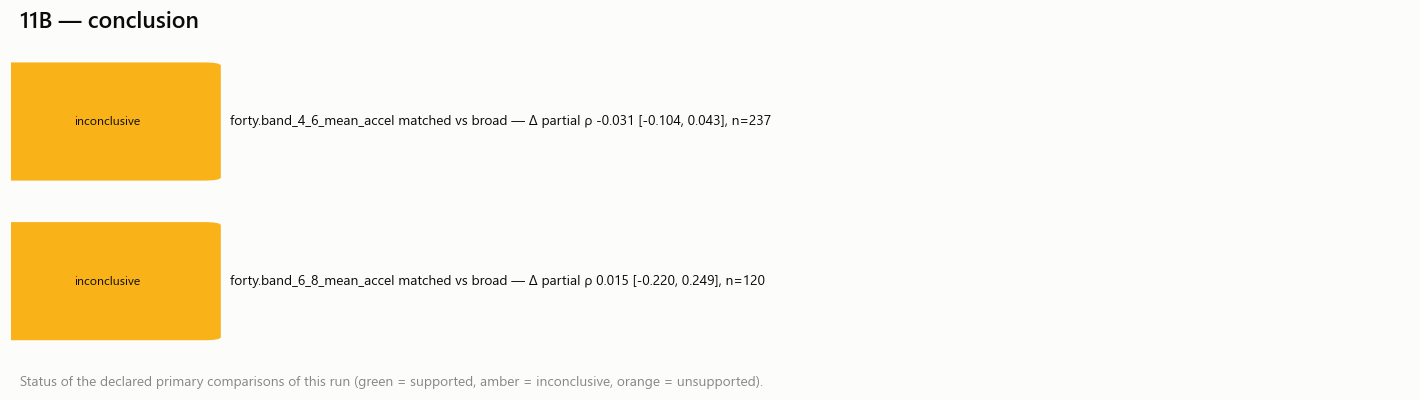

Send back: the checks, sprint checks, envelope summary, the association and held-out tables, the primary table, the sensitivity pivot and the conclusion.
Next: 11c_braking_turning_reacceleration.ipynb


In [11]:
evid = []
rep = asm.foundation(store, 'm11_repeatability')
icc = {r['feature']: r for r in rep.iter_rows(named=True)}
for r in assoc.filter((pl.col('status') == 'computed') & pl.col('kind').is_in(['matched', 'physics'])).iter_rows(named=True):
    h = held.filter((pl.col('combine') == r['combine']) & (pl.col('target') == r['nfl'])) if held.height else held
    h = h.row(0, named=True) if h.height else {}
    red = ev.stopwatch_redundancy(data, r['combine']) if r['combine'] in data.columns else {}
    evid.append(tn.evidence_row(r['combine'], '11B', n_athletes=r['n_athletes'], icc=(icc.get(r['combine']) or {}).get('icc'), icc_lo=(icc.get(r['combine']) or {}).get('icc_lo'),
                                stopwatch_r2=red.get('r2_official'), nfl_comparison=r['nfl'], cross_domain_rho=r['spearman'], cross_domain_lo=r['spearman_lo'],
                                cross_domain_hi=r['spearman_hi'], expected_sign=1, delta_rmse=h.get('delta_rmse'), delta_lo=h.get('delta_lo'), delta_hi=h.get('delta_hi'),
                                beats_controls=None, execution_mode=controls.run_mode, config_hash=C.hash()))
for k in ('lin_A0', 'lin_V0'):
    evid.append(tn.evidence_row(f'env.{k}', '11B', n_athletes=n_sup, nfl_reliability=RELMAP.get(f'env.{k}'), execution_mode=controls.run_mode, config_hash=C.hash(), note='NFL-side metric'))
te = data.select('nfl_id', (pl.col('env.lin_A0') / pl.col('forty.phase_A0')).alias('x')).drop_nulls() if {'env.lin_A0', 'forty.phase_A0'} <= set(data.columns) else pl.DataFrame({'x': []})
evid.append(tn.evidence_row('derived.transfer_efficiency_A0', '11B', n_athletes=te.height, execution_mode=controls.run_mode, config_hash=C.hash(), note='post-draft descriptor'))
# sprint phase compensation: within-position z(late band) − z(early band), per attempt, then repeatability
pc = (w.join(officials.select('nfl_id', 'position_group'), on='nfl_id').with_columns(
      [((pl.col(c) - pl.col(c).mean().over('position_group')) / pl.col(c).std().over('position_group')).alias(c + '_z') for c in ('forty.band_6_8_mean_accel', 'forty.band_2_4_mean_accel')])
      .with_columns((pl.col('forty.band_6_8_mean_accel_z') - pl.col('forty.band_2_4_mean_accel_z')).alias('value'), pl.lit('forty.phase_compensation').alias('feature')))
pcr = ev.repeatability_table(pc.select('nfl_id', 'feature', 'value').drop_nulls(), seed=C.seed)
evid.append(tn.evidence_row('forty.phase_compensation', '11B', n_athletes=int(pc.drop_nulls('value')['nfl_id'].n_unique()), icc=pcr['icc'][0] if pcr.height else None,
                            icc_lo=pcr['icc_lo'][0] if pcr.height else None, execution_mode=controls.run_mode, config_hash=C.hash()))
E = tn.evidence_frame(evid)
W(E, 'm11_metric_evidence_11B')
verd = prim['verdict'].to_list() if 'verdict' in prim.columns else []
status = rp.comparison_status(verd)
facts = {'status': status, 'run_mode': controls.run_mode,
         'sample': f"{data.height} linked athletes with ≥ 1 supported NFL target; {n_sup} supported envelopes; positions {', '.join(sorted(data['position_group'].drop_nulls().unique().to_list()))}.",
         'evidence': [f"{r['combine']}: matched partial ρ {rp.fmt(r.get('partial_matched'))} vs broad {rp.fmt(r.get('partial_broad'))}, difference {rp.ci(r.get('difference'), r.get('diff_lo'), r.get('diff_hi'))} (n={r['n_athletes']}) — {r.get('verdict')}" for r in prim.iter_rows(named=True)]
                     + [f"{r['combine']} → {r['target']}: Δ RMSE {rp.ci(r['delta_rmse'], r['delta_lo'], r['delta_hi'], 4)} ({r['verdict']})" for r in (held.iter_rows(named=True) if held.height else [])][:8]
                     + [f"sprint check — {r['check']}: ρ {rp.fmt(r['spearman'])}, median difference {rp.fmt(r['median_difference'])}" for r in sprint.iter_rows(named=True)],
         'alternatives': ['Role and play design decide when athletes accelerate in games: a band value mixes capacity and opportunity.', 'Speed and body size are shared causes of Combine and NFL values; position is in every model but not every within-position difference.',
                          'Measurement error attenuates every association (see the disattenuated column).'],
         'relevance': 'Shows whether speed-state-specific Combine acceleration says more about game acceleration in the same speed state than broad season averages do — descriptive and held-out evidence only.',
         'limitations': ['One cohort; held-out gains are exploratory until an independent cohort confirms them.', 'Envelopes reflect observed effort, not capacity.', '10 Hz limits the 2 → 4 yd/s band (few frames).'],
         'next': ['Confirm any positive matched-band result on a later draft class.', 'Condition NFL band values on play context (07A machinery) and repeat the primary.']}
md_ = rp.conclusion_markdown('11B', facts)
display(Markdown(md_))
rp.write_conclusion(store, '11B', md_)
rp.run_manifest(store, '11B', PROV, ['m11_envelopes', 'm11_speed_state_assoc', 'm11_speed_state_heldout', 'm11_speed_state_primary', 'm11_metric_evidence_11B'], status)
crow = pl.DataFrame([{'item': f"{r['combine']} matched vs broad", 'evidence': f"Δ partial ρ {rp.ci(r.get('difference'), r.get('diff_lo'), r.get('diff_hi'))}, n={r['n_athletes']}",
                      'status': rp.comparison_status([r.get('verdict')])} for r in prim.iter_rows(named=True)])
store.show(fg.fig_conclusion(crow, '11B — conclusion', 'Status of the declared primary comparisons of this run (green = supported, amber = inconclusive, orange = unsupported).'),
           'AM11_B_10_conclusion', {}, publication=True, source='m11_speed_state_primary')
print('Send back: the checks, sprint checks, envelope summary, the association and held-out tables, the primary table, the sensitivity pivot and the conclusion.')
print('Next: 11c_braking_turning_reacceleration.ipynb')